EDUCATION = 0 -> 4: 14 mẫu
EDUCATION = 5 -> 4: 280 mẫu
EDUCATION = 6 -> 4: 51 mẫu
MARRIAGE = 0 -> 3: 54 mẫu
Loại bản ghi trùng hoàn toàn: 35 dòng (còn 29965)


c:\Users\Quynh Anh\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\Quynh Anh\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\Quynh Anh\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\Quynh Anh\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packa

,issue,split,config,use_derived,n_dims,seed,pr_auc,f1_default,bal_acc,roc_auc
0,16,7:3,with_derived_33d,True,33,0,0.510250,0.463018,0.652040,0.714581
1,16,7:3,with_derived_33d,True,33,1,0.527975,0.467626,0.654456,0.723559
2,16,7:3,with_derived_33d,True,33,2,0.518884,0.467848,0.654525,0.723831
3,16,7:3,with_derived_33d,True,33,3,0.522243,0.474397,0.657639,0.726120
4,16,7:3,with_derived_33d,True,33,4,0.505364,0.449048,0.645218,0.716163
5,16,7:3,no_derived_29d,False,29,0,0.508907,0.449916,0.645604,0.712958
6,16,7:3,no_derived_29d,False,29,1,0.531463,0.461590,0.651320,0.730359
7,16,7:3,no_derived_29d,False,29,2,0.522747,0.463221,0.652148,0.727670
8,16,7:3,no_derived_29d,False,29,3,0.520089,0.463594,0.652248,0.728422
9,16,7:3,no_derived_29d,False,29,4,0.506332,0.438225,0.640034,0.716930


pr_auc           f1_default             bal_acc  \
                             mean       std       mean       std      mean   
config           n_dims                                                      
no_derived_29d   29      0.517907  0.010331   0.455309  0.011086  0.648271   
with_derived_33d 33      0.516943  0.009116   0.464387  0.009485  0.652776   

                                    roc_auc            
                              std      mean       std  
config           n_dims                                
no_derived_29d   29      0.005365  0.723268  0.007789  
with_derived_33d 33      0.004669  0.720851  0.005130

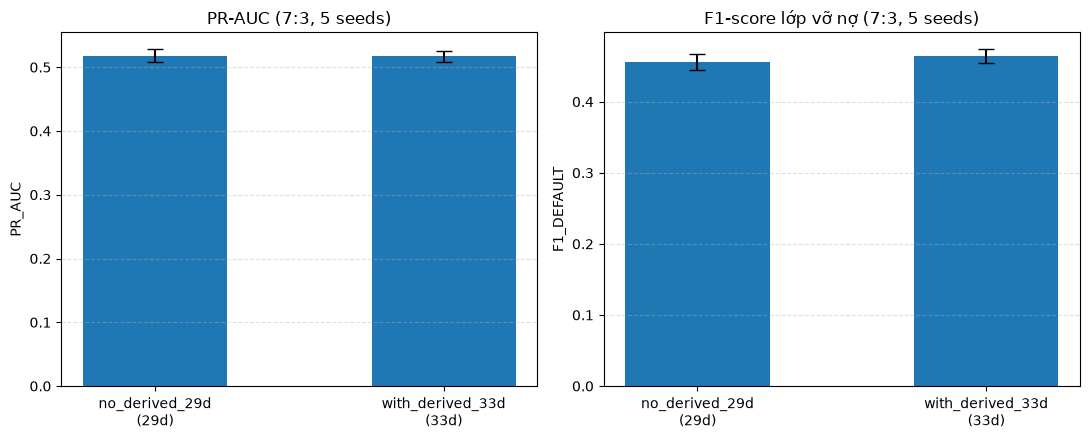

In [5]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from sklearn.metrics import (
    average_precision_score,
    balanced_accuracy_score,
    f1_score,
    roc_auc_score,
)
from sklearn.svm import SVC

from src.data import TARGET, load_raw
from src.preprocess import add_derived_features, build_preprocessor, clean, make_splits

# 1. Đọc cấu hình từ configs/experiment.yaml
with open(PROJECT_ROOT / "configs/experiment.yaml", encoding="utf-8") as f:
    cfg = yaml.safe_load(f)

seeds = cfg["seeds"]  # [0, 1, 2, 3, 4]
ratio_73 = {"7:3": cfg["splits"]["7:3"]}  # {"7:3": 0.3}

# 2. Đọc, làm sạch và chuẩn bị 2 dạng dữ liệu (33 chiều vs 29 chiều)
df_clean = clean(load_raw())
X_base = df_clean.drop(columns=[TARGET])
y = df_clean[TARGET]
X_derived = add_derived_features(X_base)

# 3. Sinh phân hoạch train/val phân tầng (7:3) theo nhãn index qua 5 seed
splits = make_splits(y, seeds=seeds, ratios=ratio_73)

records = []
for cfg_name, use_derived, X_full in [
    ("with_derived_33d", True, X_derived),
    ("no_derived_29d", False, X_base),
]:
    for seed in seeds:
        tr_idx, va_idx = splits[("7:3", seed)]

        # Cắt tập bằng .loc theo nhãn index gốc (tránh data leakage)
        X_tr_raw, y_tr = X_full.loc[tr_idx], y.loc[tr_idx]
        X_va_raw, y_va = X_full.loc[va_idx], y.loc[va_idx]

        # Fit bộ tiền xử lý CHỈ trên tập train
        prep = build_preprocessor(use_derived=use_derived)
        X_tr = prep.fit_transform(X_tr_raw, y_tr)
        X_va = prep.transform(X_va_raw)

        # Huấn luyện mô hình trên tập train và đánh giá trên tập validation
        clf = SVC(kernel="rbf", probability=True, random_state=seed)
        clf.fit(X_tr, y_tr)

        y_prob = clf.predict_proba(X_va)[:, 1]
        y_pred = clf.predict(X_va)

        records.append(
            {
                "issue": 16,
                "split": "7:3",
                "config": cfg_name,
                "use_derived": use_derived,
                "n_dims": X_tr.shape[1],
                "seed": seed,
                "pr_auc": average_precision_score(y_va, y_prob),
                "f1_default": f1_score(y_va, y_pred, pos_label=1),
                "bal_acc": balanced_accuracy_score(y_va, y_pred),
                "roc_auc": roc_auc_score(y_va, y_prob),
            }
        )

df_res = pd.DataFrame(records)
summary = (
    df_res.groupby(["config", "n_dims"])[["pr_auc", "f1_default", "bal_acc", "roc_auc"]]
    .agg(["mean", "std"])
)
display(df_res)
display(summary)

# 4. Vẽ biểu đồ so sánh 33 chiều vs 29 chiều qua 5 seed
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

for ax, metric, title in zip(
    axes,
    ["pr_auc", "f1_default"],
    ["PR-AUC (7:3, 5 seeds)", "F1-score lớp vỡ nợ (7:3, 5 seeds)"],
):
    means = summary[metric]["mean"]
    stds = summary[metric]["std"]
    labels = [f"{idx[0]}\n({idx[1]}d)" for idx in means.index]
    x_pos = np.arange(len(labels))

    ax.bar(x_pos, means.values, yerr=stds.values, capsize=6, width=0.5)
    ax.set_xticks(x_pos)
    ax.set_xticklabels(labels)
    ax.set_title(title)
    ax.set_ylabel(metric.upper())
    ax.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
out_fig_dir = PROJECT_ROOT / "results/figures"
out_fig_dir.mkdir(parents=True, exist_ok=True)
fig_path = out_fig_dir / "issue16_derived_33d_vs_29d_7-3.png"
plt.savefig(fig_path, dpi=150, bbox_inches="tight")
plt.show()